### Performing LOO-PIT on Field-Level MCMCs with Fixed Initial Conditions

This code book performs LOO-PIT analysis on an MCMC chain provided by Hugo Simon and Arnaud Di Mattia (University of Paris-Saclay). 
The chains are Field-Level inference chains of galaxy density counts over a 32 x 32 x 32 voxel space.
These chains specifically have their initial conditions fixed and only samples over the cosmological parameters. 

First we load the necessary packages

In [18]:
Pkg.instantiate()
Pkg.resolve()

In [19]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [20]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

We begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

The chains provided are a single file, which is loaded below. 

In [21]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/32_nonlinear/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-1.73421 -0.0699145 … -0.448125 -1.79911; -3.26334 -0.24600…
  "logpdf_mesh" => [-4.01379 -4.69933 … -3.64573 -4.05531; -5.15125 -3.88579 … …

For the process of PSIS, we need the logpdf_mesh field, which are the log probabilities of each voxel that the chain has determined by fitting the model to the full data set. That is, the logpdf_mesh represent $p(y | \theta)$

In [22]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -4.01379  -4.69933  -5.07896  -5.97102  …  -4.40198  -3.64573  -4.05531
 -5.15125  -3.88579  -4.42037  -4.043       -3.73739  -3.73347  -3.58681
 -4.09432  -3.83176  -3.59379  -4.66689     -4.4652   -6.89291  -3.73358
 -3.59133  -3.87445  -3.66553  -3.74406     -3.64485  -3.59223  -3.68776

[:, :, 2, 1, 1] =
 -3.6391   -3.75744  -3.76958  -3.86603  …  -3.63571  -4.63488  -4.00696
 -4.1479   -5.93984  -5.32483  -3.58714     -4.33659  -4.14465  -5.20813
 -4.95686  -4.1377   -3.58269  -3.6783      -4.94519  -4.47414  -3.58271
 -3.66997  -3.80994  -4.22621  -7.24136     -7.43669  -4.38821  -3.62027

[:, :, 3, 1, 1] =
 -3.83743  -4.57149  -4.11184  -4.95028  …  -3.82281  -3.75418  -3.64706
 -4.44083  -3.59583  -4.33865  -3.61544     -3.79916  -3.58654  -3.63691
 -3.58811  -3.5898   -3.60126  -4.15594     -3.58436  -3.6291   -3.59063
 -3.79755  -4.32484  -5.02455  -3.60825     -4.19668  -3.58266  -3.58718

;;; … 

[:, :, 30, 1, 1] =
 -4.97

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel.

Below, we create an array of vectors called logpdf_mesh to store the data from the file. Each of the 32 x 32 x 32 elements has a vector corresponding to a single voxel, and the vector holds the log probability values.

In [23]:
logpdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logpdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logpdf_mesh[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
end

Thus, log_pdf is a data object representing the 32 x 32 x 32 voxels, with each element holding 2048 log probability values collected from the file.

In [24]:
logpdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-4.01379, -5.15125, -4.09432, -3.59133, -4.69933, -3.88579, -3.83176, -3.87445, -5.07896, -4.42037  …  -4.4652, -3.64485, -3.64573, -3.73347, -6.89291, -3.59223, -4.05531, -3.58681, -3.73358, -3.68776]   …  [-4.40927, -3.70876, -3.78444, -4.09493, -3.59906, -3.58669, -3.5964, -3.78667, -3.86386, -3.60316  …  -4.50342, -3.59906, -4.14469, -3.60722, -3.63002, -3.59596, -3.71036, -3.59931, -3.58535, -3.63907]
 [-3.6391, -4.1479, -4.95686, -3.66997, -3.75744, -5.93984, -4.1377, -3.80994, -3.76958, -5.32483  …  -4.94519, -7.43669, -4.63488, -4.14465, -4.47414, -4.38821, -4.00696, -5.20813, -3.58271, -3.62027]        [-5.6575, -3.64438, -3.71983, -3.59301, -3.60474, -3.58264, -3.73228, -4.00395, -4.18207, -4.5038  …  -3.831, -3.60569, -3.70446, -4.27731, -5.94799, -4.8667, -4.61906, -3.86972, -3.68644, -3.59085]
 [-3.83743, -4.44083, -3.58811, -3.79755, -4.57149, -3.59583, -3.5898, -4.32484, -4.11184, -4.33865  …  -3.58436, -4.19668, -3.75418

In [25]:
logpdf_mesh[3,16,4]

2048-element Vector{Float64}:
 -4.39378956045086
 -4.391776019179472
 -5.118065718543226
 -3.685016388415225
 -3.664730078787899
 -3.6872877414635785
 -3.906340550919297
 -3.6458712882101194
 -5.318231462498028
 -3.6977349990320434
  ⋮
 -3.587419781256381
 -3.5855097350552585
 -3.838637659691864
 -3.6090448054403708
 -5.203655324952355
 -3.7063766663693687
 -3.772182862490685
 -4.052078503839246
 -4.3865548800700775

Next, we perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of log pdf probabilities.

In [26]:
psis_result = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
for i in 1:32, j in 1:32, k in 1:32
    psis_result[i, j, k] = psis(-logpdf_mesh[i,j,k])
end

The importance weights and the pareto shape values are stored in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [27]:
psis_weights = Array{Vector{Float64}}(undef, 32, 32, 32)
for i in 1:32, j in 1:32, k in 1:32
    psis_weights[i,j,k] = psis_result[i,j,k].weights
end

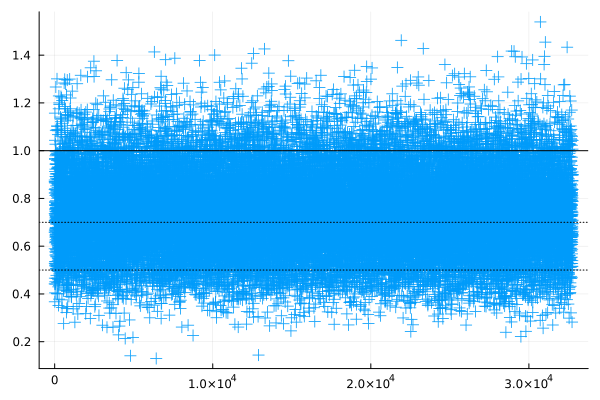

In [28]:
pareto_shapes = []
for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes, psis_result[i,j,k].pareto_shape)
end

psis_plot = Plots.scatter(pareto_shapes; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

The plot above is of the Pareto shape parameters from PSIS. Because the shape parameters are all under the threshhold of 0.5, this informs that the importance sampling is well-behaved and reliable for probability reweighting in the Leave One Out approach.

Now that we know the weights are reliable, we can proceed with the LOO-PIT analysis. The PSIS weights inform how to reweight $p(y | \theta)$ determined by the MCMC logpdf_mesh field, into $p(y_{-i} | \theta)$, the LOO probability density. 

First load the logcdf_mesh field from the MCMC chain file. Similar to logpdf_mesh, this field has contains 4 x 512 samples corresponding to the CDF of that particular voxel. It is stored below in an array with each voxel having an array of all CDF samples

In [30]:
logcdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logcdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logcdf_mesh[i,j,k], vec(f["logcdf_mesh"][:,:,i,j,k]))
end

In [31]:
logcdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-1.73421, -3.26334, -1.85884, -0.804205, -0.0699145, -0.246003, -0.274599, -1.50312, -0.0427195, -2.32524  …  -2.38609, -1.0158, -0.448125, -1.23305, -5.2903, -0.810055, -1.79911, -0.769031, -1.23329, -0.390477]                        …  [-0.104531, -0.367772, -0.304624, -0.169259, -0.558671, -0.623593, -0.834607, -1.34148, -0.256994, -0.868282  …  -2.43749, -0.558655, -0.156082, -0.886245, -0.47653, -0.571103, -1.18218, -0.557727, -0.635725, -0.459533]
 [-0.998641, -1.93916, -3.02264, -1.08479, -1.28319, -4.20271, -1.92401, -1.38604, -1.30775, -3.47461  …  -3.00803, -5.89667, -2.61141, -1.93434, -2.39815, -2.2812, -1.7234, -3.33291, -0.70477, -0.936843]                                    [-0.0210396, -1.01443, -0.356937, -0.584543, -0.539002, -0.686864, -1.23051, -0.197616, -1.98947, -0.0913866  …  -0.275038, -0.536033, -1.1687, -2.12652, -0.0149246, -2.90925, -0.077927, -1.49481, -0.39201, -0.595856]
 [-1.43697, -0.0999035, -0.612922,

The CDF values are then able to be systemically reweighted by the PSIS weights in order to obtain the LOO-PIT final values.

In [32]:
loo_pit = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            loo_pit[i,j,k] = dot(psis_weights[i,j,k], exp.(logcdf_mesh[i,j,k]))
        end
    end
end

Plotting the LOO-PIT values in a histogram, we see the approximately uniform distribution of values as expected from a MCMC sampling based on a strong model.

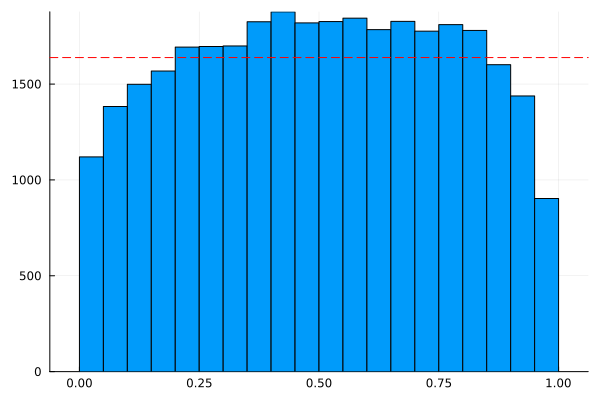

In [33]:
Plots.histogram(vec(loo_pit), legend=false, bins=20)
hline!([length(loo_pit) / 20], color=:red, linestyle=:dash)